# FER-2013 Facial Expression Recognition

## Phase 1: Exploratory Data Analysis (EDA) & Data Preprocessing

**Group:** 3 (Atria University - Neural Network and CNN Sprint)  
**Dataset:** FER-2013 (Facial Expression Recognition 2013)  
**Dataset Source:** [Kaggle FER-2013 Challenge](https://www.kaggle.com/datasets/msambare/fer2013)  
**Target:** 7-class emotion classification (`angry`, `disgust`, `fear`, `happy`, `sad`, `surprise`, `neutral`)  
**Framework:** TensorFlow / Keras & NumPy / Scikit-Learn

---

### Notebook Outline
1. **Environment Setup & Dataset Loading**
   - Environment initialization, reproducibility seed configuration, and directory validation.
   - Raw image counting across splits and emotion classes.
2. **Exploratory Data Analysis (EDA)**
   - Class distribution and severe imbalance analysis (`disgust` minority vs. `happy` majority).
   - Sample grid visualization ($7 \times 5$ matrix of emotion samples via reproducible random sampling).
   - Pixel intensity distribution analysis.
   - Pixel-wise mean image calculation (average face per emotion).
3. **Data Quality, Integrity & Noise Analysis**
   - Dimension ($48 \times 48$) and grayscale format mode (`'L'`) verification.
   - Detection and visualization of completely blank/black corrupted images (using exact relative paths).
   - Dark-image pixel distribution analysis (lighting variations vs. blank images).
   - Duplicate detection on decoded pixel content (retaining all paths).
   - Cross-split benchmark data leakage analysis.
   - Label noise discovery: duplicate groups with contradictory emotion annotations.
4. **Data Cleaning, Splitting & Preprocessing Pipeline**
   - Cleaning: excluding 11 completely black training images using exact paths; preserving the official 7,178-image test set intact.
   - Stratified group-aware train/validation split (80/20 ratio preserving class proportions with zero duplicate leakage across partitions).
   - Pixel normalization to $[0.0, 1.0]$ and channel dimension addition ($48 \times 48 \times 1$).
   - Numerical label encoding ($0$ to $6$).
   - Comprehensive assertion test suite (counts, shapes, ranges, absence of black images).
   - Exporting preprocessed arrays to `processed/fer2013_preprocessed.npz`.
5. **Final Dataset Verification & Summary**
   - Re-loading and bitwise comparison of the saved archive against in-memory arrays.


### 1. Environment Setup and Dataset Loading


In [30]:
# Import required libraries
import os
import hashlib
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

# Fix random seed for reproducibility across splits and sampling
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Set plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.size"] = 10

print("All libraries imported successfully!")
print(f"Reproducibility seed fixed at: {RANDOM_SEED}")


All libraries imported successfully!
Reproducibility seed fixed at: 42


### 1.1 Dataset Location and Emotion Categories


In [31]:
# Dynamic dataset path resolution (supports running from repo root or notebooks/ folder)
dataset_path = "../data" if os.path.exists("../data") else "data"

# Seven standard emotion categories in FER-2013
classes = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]

print("Dataset path:", os.path.abspath(dataset_path))
print("Emotion categories (7 classes):", classes)


Dataset path: c:\Users\Meghna\OneDrive\Desktop\facial-expression-recognition\data
Emotion categories (7 classes): ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


### 1.2 Verifying Dataset Directory Structure


In [32]:
# Verify existence of train and test folders along with all 7 emotion sub-folders
for split in ["train", "test"]:
    print(f"\nChecking {split.upper()} split:")
    split_dir = os.path.join(dataset_path, split)
    if not os.path.exists(split_dir):
        print(f"Directory missing: {split_dir}")
        continue
    for emotion in classes:
        folder = os.path.join(split_dir, emotion)
        status = "Folder exists" if os.path.exists(folder) else "MISSING"
        print(f"  {emotion:<10} -> {status}")



Checking TRAIN split:
  angry      -> Folder exists
  disgust    -> Folder exists
  fear       -> Folder exists
  happy      -> Folder exists
  sad        -> Folder exists
  surprise   -> Folder exists
  neutral    -> Folder exists

Checking TEST split:
  angry      -> Folder exists
  disgust    -> Folder exists
  fear       -> Folder exists
  happy      -> Folder exists
  sad        -> Folder exists
  surprise   -> Folder exists
  neutral    -> Folder exists


### 1.3 Counting Raw Images in Each Emotion Category


In [33]:
# Count image files in each emotion subfolder
image_counts = []

for split in ["train", "test"]:
    for emotion in classes:
        folder = os.path.join(dataset_path, split, emotion)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        image_counts.append({
            "Dataset": split,
            "Emotion": emotion,
            "Number of Images": count
        })

df_counts = pd.DataFrame(image_counts)
print(df_counts)


   Dataset   Emotion  Number of Images
0    train     angry              3995
1    train   disgust               436
2    train      fear              4097
3    train     happy              7215
4    train       sad              4830
5    train  surprise              3171
6    train   neutral              4965
7     test     angry               958
8     test   disgust               111
9     test      fear              1024
10    test     happy              1774
11    test       sad              1247
12    test  surprise               831
13    test   neutral              1233


In [34]:
# Calculate total counts across splits
train_total = df_counts[df_counts["Dataset"] == "train"]["Number of Images"].sum()
test_total = df_counts[df_counts["Dataset"] == "test"]["Number of Images"].sum()
grand_total = df_counts["Number of Images"].sum()

print(f"Training images: {train_total}")
print(f"Testing images:  {test_total}")
print(f"Total images:    {grand_total}")


Training images: 28709
Testing images:  7178
Total images:    35887


### 1.4 Inspecting a Single Sample Image


Sample file:       Training_10019449.jpg
Image dimensions:  (48, 48)
Image mode:        L


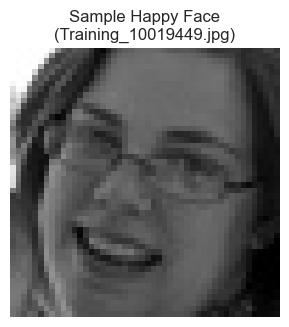

In [35]:
# Inspect a single sample image from the training set
sample_folder = os.path.join(dataset_path, "train", "happy")
sample_image_name = sorted(os.listdir(sample_folder))[0]
sample_image_path = os.path.join(sample_folder, sample_image_name)

img = Image.open(sample_image_path)

print("Sample file:      ", sample_image_name)
print("Image dimensions: ", img.size)
print("Image mode:       ", img.mode)

plt.figure(figsize=(3.5, 3.5))
plt.imshow(img, cmap="gray")
plt.title(f"Sample Happy Face\n({sample_image_name})")
plt.axis("off")
plt.show()


### 2. Exploratory Data Analysis (EDA)


### 2.1 Class Distribution Analysis & Class Imbalance


Training Class Distribution & Percentages:
 Emotion  Number of Images  Percentage
   angry              3995   13.915497
 disgust               436    1.518688
    fear              4097   14.270786
   happy              7215   25.131492
     sad              4830   16.823992
surprise              3171   11.045317
 neutral              4965   17.294228


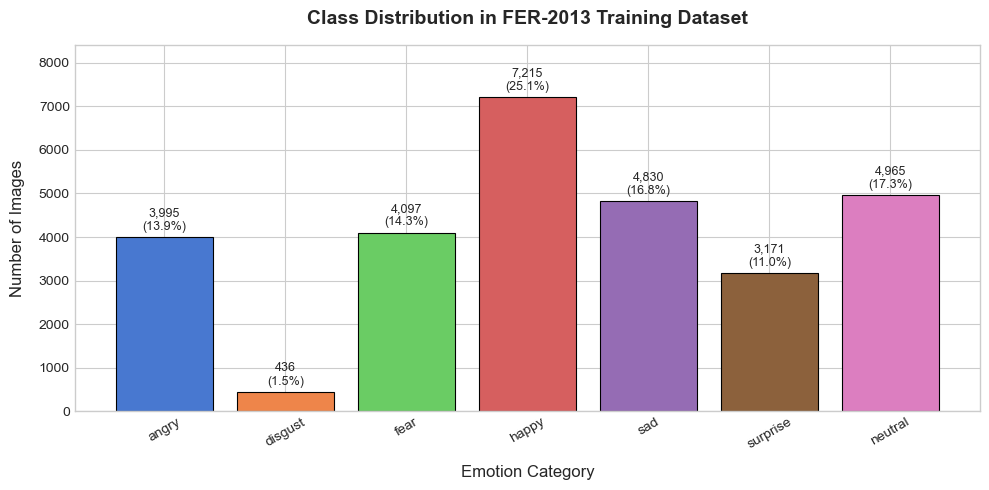

In [36]:
# Analyze training class proportions
train_counts = df_counts[df_counts["Dataset"] == "train"].copy()
train_counts["Percentage"] = (train_counts["Number of Images"] / train_counts["Number of Images"].sum()) * 100

print("Training Class Distribution & Percentages:")
print(train_counts[["Emotion", "Number of Images", "Percentage"]].to_string(index=False))

# Visualize class distribution with percentages
plt.figure(figsize=(10, 5))
palette = sns.color_palette("muted", len(classes))
bars = plt.bar(train_counts["Emotion"], train_counts["Number of Images"], color=palette, edgecolor="black", linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / train_counts['Number of Images'].sum()) * 100
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 100, f"{yval:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)

plt.title("Class Distribution in FER-2013 Training Dataset", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Emotion Category", fontsize=12, labelpad=10)
plt.ylabel("Number of Images", fontsize=12, labelpad=10)
plt.ylim(0, max(train_counts["Number of Images"]) + 1200)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Observations & Inferences on Class Imbalance:**
- **Dominant Class:** `happy` has the highest representation with **7,215 images (25.13%)**.
- **Severe Minority Class:** `disgust` has only **436 images (1.52%)**. The ratio between `happy` and `disgust` is over **16.5 to 1**.
- **Imbalance Consequence:** A standard neural network could achieve ~25% accuracy simply by predicting `happy` for every input. Overall accuracy is therefore an insufficient metric.
- **Project Brief Requirement:** As mandated in the brief, we must evaluate models using **Macro-F1, per-class Precision, and per-class Recall**, and plan for class-weighted loss or oversampling techniques in Phase 3.


### 2.2 Visual Inspection: Sample Image Grid Across All 7 Emotions (Reproducible Random Sampling)


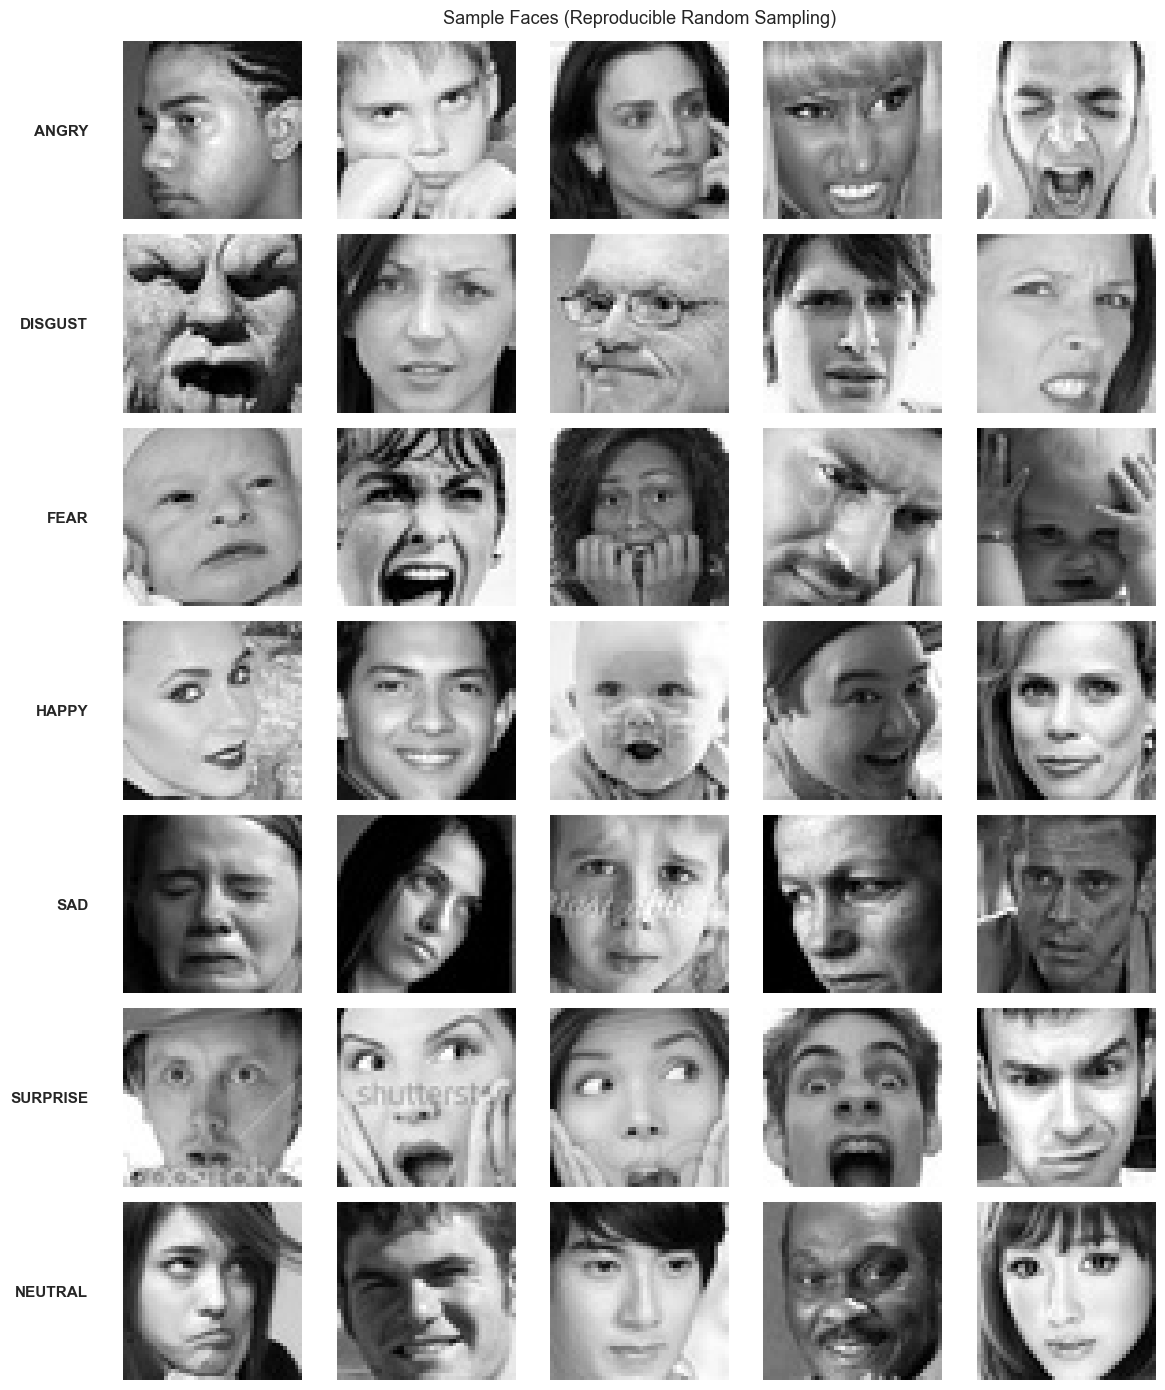

In [37]:
# Display a 7x5 grid using reproducible random sampling across each emotion category
rng = np.random.RandomState(RANDOM_SEED)

plt.figure(figsize=(12, 14))

for row, emotion in enumerate(classes):
    folder = os.path.join(dataset_path, "train", emotion)
    all_files = sorted([f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    
    # Reproducible random sampling of 5 distinct images per class
    sampled_files = rng.choice(all_files, size=5, replace=False)
    
    for col, image_file in enumerate(sampled_files):
        image_path = os.path.join(folder, image_file)
        img = Image.open(image_path)
        
        plt.subplot(7, 5, row * 5 + col + 1)
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        
        if col == 0:
            plt.text(-10, 24, emotion.upper(), fontsize=11, fontweight="bold", ha="right", va="center")
        if row == 0 and col == 2:
            plt.title("Sample Faces (Reproducible Random Sampling)", fontsize=13, pad=12)

plt.tight_layout()
plt.show()


In [38]:
# Check pixel intensity statistics across sample training images
sample_files = sorted(os.listdir(os.path.join(dataset_path, "train", "angry")))[:5]

print("Pixel Intensity Statistics for 5 Angry Training Samples:")
print(f"{'Filename':<25} | {'Min':>4} | {'Max':>4} | {'Mean':>7} | {'Std':>7}")
print("-" * 60)

for filename in sample_files:
    path = os.path.join(dataset_path, "train", "angry", filename)
    arr = np.array(Image.open(path).convert("L"))
    print(f"{filename:<25} | {arr.min():>4} | {arr.max():>4} | {arr.mean():>7.2f} | {arr.std():>7.2f}")


Pixel Intensity Statistics for 5 Angry Training Samples:
Filename                  |  Min |  Max |    Mean |     Std
------------------------------------------------------------
Training_10118481.jpg     |    3 |  197 |  106.00 |   51.09
Training_10120469.jpg     |    0 |  255 |   98.21 |   69.56
Training_10131352.jpg     |    0 |    0 |    0.00 |    0.00
Training_10161559.jpg     |    0 |  252 |  116.59 |   51.40
Training_1021836.jpg      |    3 |  238 |  163.68 |   39.02


### 2.3 Average Face for Each Emotion (Pixel-Wise Mean Image)


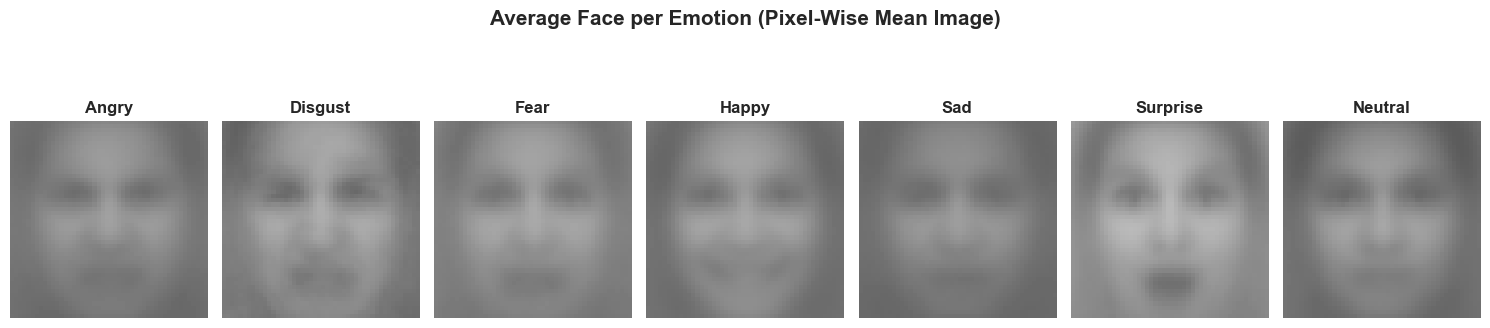

In [39]:
# Calculate pixel-wise average face for each emotion class
average_faces = {}

for emotion in classes:
    folder = os.path.join(dataset_path, "train", emotion)
    images = []
    
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        img = Image.open(path).convert("L")
        images.append(np.array(img, dtype=np.float32))
        
    average_faces[emotion] = np.mean(images, axis=0)

# Display the average face for all seven emotions
plt.figure(figsize=(15, 3.5))
for i, emotion in enumerate(classes):
    plt.subplot(1, 7, i + 1)
    plt.imshow(average_faces[emotion], cmap="gray", vmin=0, vmax=255)
    plt.title(emotion.capitalize(), fontsize=12, fontweight="bold")
    plt.axis("off")

plt.suptitle("Average Face per Emotion (Pixel-Wise Mean Image)", fontsize=15, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()


**Observations & Inferences on Average Faces:**
- **Visual Features:** Distinct global patterns emerge despite facial diversity:
  - `happy`: Exhibits a visibly lighter, wider oral fissure indicative of teeth and smiles.
  - `surprise`: Displays a distinct, dark, open elliptical mouth region and raised brow highlights.
  - `angry` & `sad`: Feature darker brow regions caused by furrowing.
- **Blurriness Rationale:** Faces in FER-2013 have subtle variations in pose, head angle, facial bone structure, and alignment. Averaging thousands of diverse faces smooths out individual features into a blurred centroid template.


### 3. Data Quality, Integrity & Noise Analysis

In accordance with the project brief:

> "Labels are noisy and some images are not faces or are ambiguous. Look at samples and discuss this honestly."

This section presents a detailed analysis of the dataset's quality, integrity, and potential label noise. The following checks were performed:

- Verifying image dimensions and image modes.
- Detecting and visualizing completely black images using their exact relative file paths.
- Performing pixel-intensity analysis to distinguish completely black images from naturally dark images.
- Identifying duplicate images using cryptographic hashes of decoded pixel content while retaining all file paths associated with each duplicate group.
- Examining duplicate overlap between the original training and testing datasets.
- Identifying duplicate image groups containing conflicting emotion labels.

### 3.1 Checking Dimensions, Color Modes and File Integrity


In [40]:
# Audit all 35,887 images for dimension errors, color modes, and file corruption
dimension_errors = []
mode_counts = defaultdict(int)
corrupted_images = []

for split in ["train", "test"]:
    for emotion in classes:
        folder = os.path.join(dataset_path, split, emotion)
        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)
            try:
                with Image.open(path) as img:
                    if img.size != (48, 48):
                        dimension_errors.append(path)
                    mode_counts[img.mode] += 1
                    img.verify()
            except Exception as e:
                corrupted_images.append((path, str(e)))

print("Images with incorrect dimensions: ", len(dimension_errors))
print("Image modes encountered:          ", dict(mode_counts))
print("Total corrupted / unreadable files:", len(corrupted_images))


Images with incorrect dimensions:  0
Image modes encountered:           {'L': 35887}
Total corrupted / unreadable files: 0


### 3.2 Detection and Visualization of Completely Blank/Black Images (Exact Relative Paths)


In [41]:
# Scan for completely blank/black images (all pixel values equal to 0) using exact relative paths
black_images = []

for split in ["train", "test"]:
    for emotion in classes:
        folder = os.path.join(dataset_path, split, emotion)
        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)
            rel_path = os.path.normpath(os.path.relpath(path, dataset_path)).replace("\\", "/")
            arr = np.array(Image.open(path).convert("L"))
            if np.all(arr == 0):
                black_images.append({
                    "split": split,
                    "emotion": emotion,
                    "filename": filename,
                    "rel_path": rel_path,
                    "path": path
                })

print(f"Total completely black images detected: {len(black_images)}")
print(f"  Training split: {sum(1 for x in black_images if x['split'] == 'train')} images")
print(f"  Testing split:  {sum(1 for x in black_images if x['split'] == 'test')} image\n")

for item in black_images:
    print(f"  [{item['split'].upper():<5}] {item['rel_path']}")


Total completely black images detected: 12
  Training split: 11 images
  Testing split:  1 image

  [TRAIN] train/angry/Training_10131352.jpg
  [TRAIN] train/angry/Training_28756096.jpg
  [TRAIN] train/angry/Training_32571770.jpg
  [TRAIN] train/angry/Training_52563817.jpg
  [TRAIN] train/angry/Training_78540321.jpg
  [TRAIN] train/angry/Training_96772745.jpg
  [TRAIN] train/angry/Training_99531165.jpg
  [TRAIN] train/happy/Training_87607167.jpg
  [TRAIN] train/sad/Training_48621797.jpg
  [TRAIN] train/surprise/Training_48403842.jpg
  [TRAIN] train/neutral/Training_89335926.jpg
  [TEST ] test/angry/PublicTest_5543497.jpg


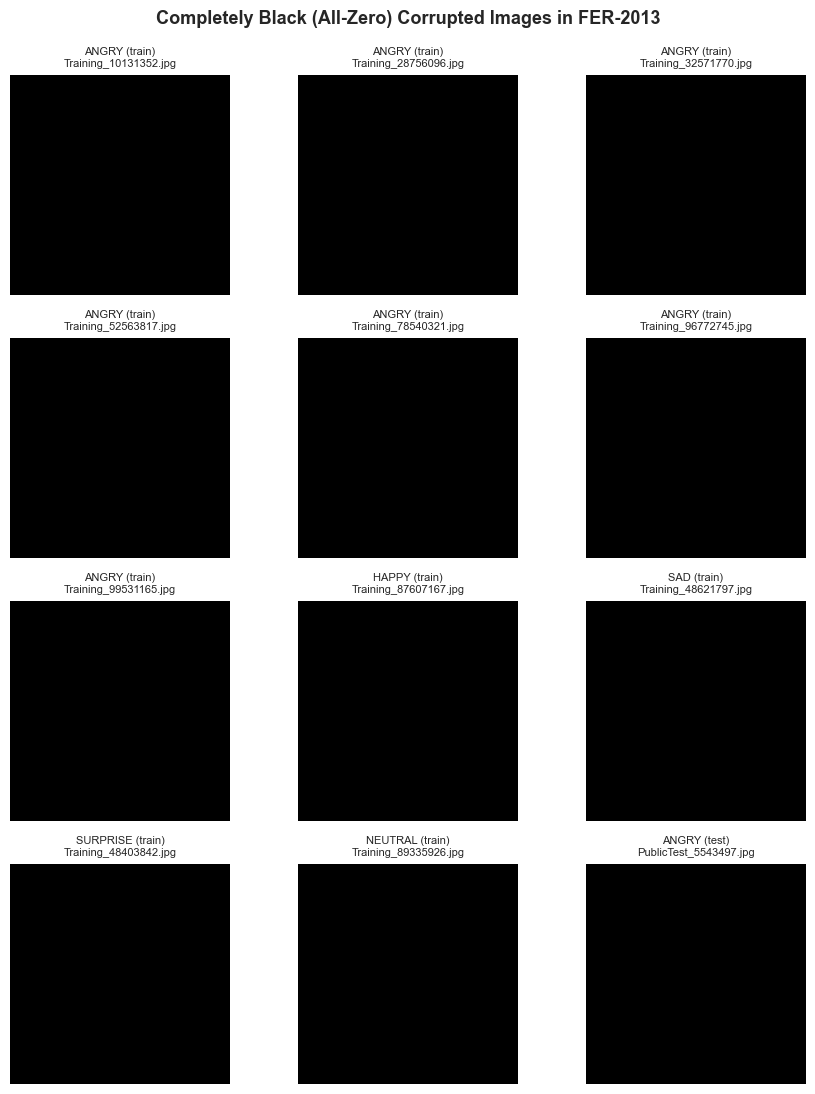

In [42]:
# Visualize all 12 completely black images
fig, axes = plt.subplots(4, 3, figsize=(9, 11))
axes = axes.flatten()

for i, item in enumerate(black_images):
    img = Image.open(item["path"]).convert("L")
    axes[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"{item['emotion'].upper()} ({item['split']})\n{item['filename']}", fontsize=8)
    axes[i].axis("off")

plt.suptitle("Completely Black (All-Zero) Corrupted Images in FER-2013", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


### 3.3 Dark-Image Pixel Intensity Analysis (Lighting Variation vs. Blank Noise)


Overall training pixel mean intensity: 129.47 ± 33.50
Images with mean brightness < 25.0 (excluding completely black): 12


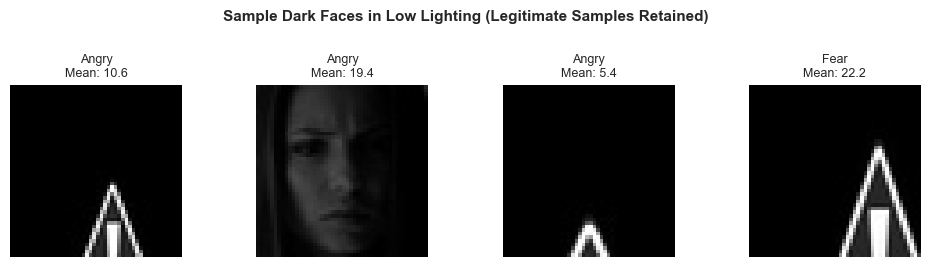

In [43]:
# Analyze dark/low-contrast images: check distribution of mean pixel brightness
train_means = []
low_brightness_samples = []

for emotion in classes:
    folder = os.path.join(dataset_path, "train", emotion)
    for filename in os.listdir(folder):
        p = os.path.join(folder, filename)
        arr = np.array(Image.open(p).convert("L"), dtype=np.float32)
        m = arr.mean()
        train_means.append(m)
        if 0 < m < 25.0:  # dark but not completely black
            low_brightness_samples.append((emotion, filename, p, m))

train_means = np.array(train_means)
print(f"Overall training pixel mean intensity: {train_means.mean():.2f} ± {train_means.std():.2f}")
print(f"Images with mean brightness < 25.0 (excluding completely black): {len(low_brightness_samples)}")

# Display 4 sample dark images to verify they contain legitimate faces in low light
if low_brightness_samples:
    plt.figure(figsize=(10, 2.5))
    for i, (emo, fname, p, m) in enumerate(low_brightness_samples[:4]):
        plt.subplot(1, 4, i + 1)
        plt.imshow(Image.open(p), cmap="gray", vmin=0, vmax=255)
        plt.title(f"{emo.capitalize()}\nMean: {m:.1f}", fontsize=9)
        plt.axis("off")
    plt.suptitle("Sample Dark Faces in Low Lighting (Legitimate Samples Retained)", fontsize=11, fontweight="bold", y=1.05)
    plt.tight_layout()
    plt.show()


### Observations on Blank vs. Dark Images

- **Completely Black Images (Mean = 0.0):** 11 images in the training set and 1 image in the test set contain only zero-value pixels, with no visible facial information. These images are considered potentially corrupted or invalid samples.

- **Low-Brightness Images (Mean > 0.0):** Some images contain faces captured under shadowed or dim lighting conditions. Although these images appear dark, they still retain visible facial features and expression-related information. Therefore, in accordance with the project brief, these legitimate dark images are preserved. Only the 11 completely black images are removed from the training set.

- **Official Test Set Preservation:** All 7,178 images in the official test set are retained without modification or removal. This preserves the original test-set size and evaluation protocol.


### 3.4 Duplicate Image Detection on Decoded Pixel Content


In [44]:
# Compute cryptographic SHA-256 hashes of DECODED pixel arrays to detect true visual duplicates
def get_pixel_hash(file_path):
    with Image.open(file_path) as img:
        arr = np.array(img.convert("L"), dtype=np.uint8)
        return hashlib.sha256(arr.tobytes()).hexdigest()

# Collect exact relative paths of all training and testing images
black_train_rel_paths = {x["rel_path"] for x in black_images if x["split"] == "train"}

clean_train_paths = []
for emo in classes:
    folder = os.path.join(dataset_path, "train", emo)
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        rel_p = os.path.normpath(os.path.relpath(p, dataset_path)).replace("\\", "/")
        if rel_p not in black_train_rel_paths:
            clean_train_paths.append(p)

all_test_paths = [
    os.path.join(dataset_path, "test", emo, f)
    for emo in classes
    for f in sorted(os.listdir(os.path.join(dataset_path, "test", emo)))
]

# Map decoded pixel hash to list of ALL associated file paths
train_pixel_map = defaultdict(list)
for p in clean_train_paths:
    train_pixel_map[get_pixel_hash(p)].append(p)

test_pixel_map = defaultdict(list)
for p in all_test_paths:
    test_pixel_map[get_pixel_hash(p)].append(p)

train_dup_groups = {h: paths for h, paths in train_pixel_map.items() if len(paths) > 1}
test_dup_groups = {h: paths for h, paths in test_pixel_map.items() if len(paths) > 1}
shared_hashes = set(train_pixel_map.keys()) & set(test_pixel_map.keys())

train_dup_images_count = sum(len(paths) for paths in train_dup_groups.values())
test_dup_images_count = sum(len(paths) for paths in test_dup_groups.values())
shared_train_instances = sum(len(train_pixel_map[h]) for h in shared_hashes)
shared_test_instances = sum(len(test_pixel_map[h]) for h in shared_hashes)

print(f"Duplicate groups within clean Training set: {len(train_dup_groups):,} groups ({train_dup_images_count:,} total images)")
print(f"Duplicate groups within official Testing set:  {len(test_dup_groups):,} groups ({test_dup_images_count:,} total images)")
print(f"Identical images shared across Train & Test:   {len(shared_hashes):,} unique hashes ({shared_train_instances:,} train + {shared_test_instances:,} test instances)")


Duplicate groups within clean Training set: 1,034 groups (2,260 total images)
Duplicate groups within official Testing set:  81 groups (167 total images)
Identical images shared across Train & Test:   530 unique hashes (692 train + 567 test instances)


### 3.5 Label Noise & Contradictory Annotation Analysis


In [45]:
# Identify duplicate groups that carry conflicting emotion labels (retaining all paths)
def get_label_from_path(p):
    return os.path.basename(os.path.dirname(p))

train_label_conflicts = []
for h, paths in train_dup_groups.items():
    labels = {get_label_from_path(p) for p in paths}
    if len(labels) > 1:
        train_label_conflicts.append(paths)

test_label_conflicts = []
for h, paths in test_dup_groups.items():
    labels = {get_label_from_path(p) for p in paths}
    if len(labels) > 1:
        test_label_conflicts.append(paths)

cross_split_conflicts = []
for h in shared_hashes:
    tr_paths = train_pixel_map[h]
    te_paths = test_pixel_map[h]
    tr_labels = {get_label_from_path(p) for p in tr_paths}
    te_labels = {get_label_from_path(p) for p in te_paths}
    combined_labels = tr_labels | te_labels

    if len(combined_labels) > 1:
        cross_split_conflicts.append((tr_paths, te_paths))

train_conflict_images = sum(len(p) for p in train_label_conflicts)
test_conflict_images = sum(len(p) for p in test_label_conflicts)

print(f"Training duplicate groups with conflicting labels: {len(train_label_conflicts)} ({train_conflict_images} total images)")
print(f"Testing duplicate groups with conflicting labels:  {len(test_label_conflicts)} ({test_conflict_images} total images)")
print(f"Cross-split duplicate groups with conflicting labels: {len(cross_split_conflicts)}")

print("\nSample Training Conflicting-Label Groups:")
for i, paths in enumerate(train_label_conflicts[:5], 1):
    annotations = [f"{get_label_from_path(p)} ({os.path.basename(p)})" for p in paths]
    print(f"  Conflict {i}: " + " vs. ".join(annotations))


Training duplicate groups with conflicting labels: 38 (96 total images)
Testing duplicate groups with conflicting labels:  4 (9 total images)
Cross-split duplicate groups with conflicting labels: 24

Sample Training Conflicting-Label Groups:
  Conflict 1: angry (Training_10857340.jpg) vs. sad (Training_33162240.jpg)
  Conflict 2: angry (Training_11036720.jpg) vs. sad (Training_4450363.jpg)
  Conflict 3: angry (Training_13919685.jpg) vs. fear (Training_19944949.jpg)
  Conflict 4: angry (Training_24511742.jpg) vs. angry (Training_96661811.jpg) vs. sad (Training_14784369.jpg)
  Conflict 5: angry (Training_29384255.jpg) vs. sad (Training_77595440.jpg)


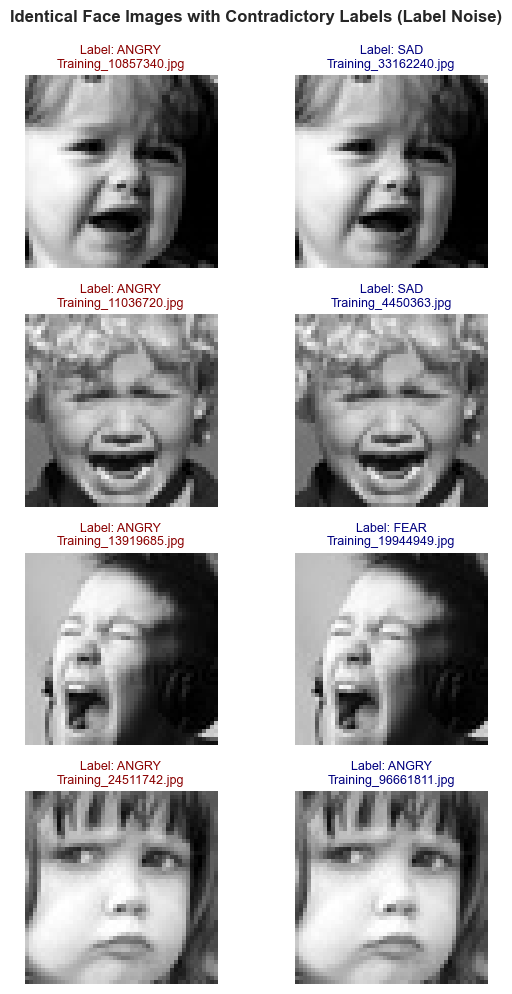

In [46]:
# Visualizing identical faces that carry contradictory emotion labels
fig, axes = plt.subplots(4, 2, figsize=(6, 10))

for i, paths in enumerate(train_label_conflicts[:4]):
    p1, p2 = paths[0], paths[1]
    lbl1, lbl2 = get_label_from_path(p1), get_label_from_path(p2)
    
    img1 = Image.open(p1).convert("L")
    img2 = Image.open(p2).convert("L")
    
    axes[i, 0].imshow(img1, cmap="gray")
    axes[i, 0].set_title(f"Label: {lbl1.upper()}\n{os.path.basename(p1)}", fontsize=9, color="darkred")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(img2, cmap="gray")
    axes[i, 1].set_title(f"Label: {lbl2.upper()}\n{os.path.basename(p2)}", fontsize=9, color="navy")
    axes[i, 1].axis("off")

plt.suptitle("Identical Face Images with Contradictory Labels (Label Noise)", fontsize=12, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


### Key Findings on Dataset Noise & Duplicate Overlap

**1. Duplicate Groups & Multiplicity:**

- **Training:** 1,034 duplicate groups containing 2,260 images (1,226 additional copies).
- **Testing:** 81 duplicate groups containing 167 images.
- **Train-Test Overlap:** 530 unique image hashes appear in both the original training and testing datasets. These shared hashes affect 692 training instances and 567 testing instances. This indicates pre-existing duplicate overlap in the original dataset and is a potential source of data leakage during model evaluation.

**2. Label Contradictions:**

- **Training:** 38 duplicate groups containing 96 images have conflicting emotion labels.
- **Train-Test Overlap:** 24 shared duplicate groups have conflicting labels across the original training and testing datasets.
- Examples include identical image content being assigned different labels, such as `angry` and `sad`, or `fear` and `surprise`.

In accordance with the project instructions, we do not arbitrarily change emotion labels or remove duplicate images based only on these observations. Instead, we document these inconsistencies as potential sources of label noise and limitations in the dataset.


### 4. Data Cleaning, Splitting & Preprocessing Pipeline


### 4.1 Cleaning Training Data (Exact Relative Paths)


In [47]:
# Clean training data by excluding the 11 completely black images using exact relative paths
raw_train_paths, raw_train_labels = [], []
for emo in classes:
    f_dir = os.path.join(dataset_path, "train", emo)
    for fname in sorted(os.listdir(f_dir)):
        raw_train_paths.append(os.path.join(f_dir, fname))
        raw_train_labels.append(emo)

# Filter matching exact relative paths
filtered_train = [
    (p, l) for p, l in zip(raw_train_paths, raw_train_labels)
    if os.path.normpath(os.path.relpath(p, dataset_path)).replace("\\", "/") not in black_train_rel_paths
]
train_paths = [item[0] for item in filtered_train]
train_labels = [item[1] for item in filtered_train]

# Official test set: preserve all 7,178 images intact
raw_test_paths, raw_test_labels = [], []
for emo in classes:
    f_dir = os.path.join(dataset_path, "test", emo)
    for fname in sorted(os.listdir(f_dir)):
        raw_test_paths.append(os.path.join(f_dir, fname))
        raw_test_labels.append(emo)

test_paths = raw_test_paths
test_labels = raw_test_labels

print(f"Clean Training images: {len(train_paths):,} (excluded exactly {len(raw_train_paths) - len(train_paths)} black images)")
print(f"Official Testing images: {len(test_paths):,} (100% preserved per benchmark protocol)")
assert len(train_paths) == len(train_labels) == 28698
assert len(test_paths) == len(test_labels) == 7178


Clean Training images: 28,698 (excluded exactly 11 black images)
Official Testing images: 7,178 (100% preserved per benchmark protocol)


### 4.2 Stratified Group-Aware Train/Validation Split (80/20 Ratio, Zero Duplicate Leakage)


In [48]:
# Map each unique pixel hash in the training set to a distinct group ID
hash_to_group = {}
train_groups = []
for p in train_paths:
    h = get_pixel_hash(p)
    if h not in hash_to_group:
        hash_to_group[h] = len(hash_to_group)
    train_groups.append(hash_to_group[h])

# Perform 5-fold Stratified Group K-Fold split (80% train / 20% validation)
# This guarantees that all identical duplicate images stay in the SAME partition,
# eliminating train-val data leakage while maintaining balanced class stratification.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
train_idx, val_idx = next(sgkf.split(train_paths, train_labels, train_groups))

X_train_paths = [train_paths[i] for i in train_idx]
y_train_raw = [train_labels[i] for i in train_idx]

X_val_paths = [train_paths[i] for i in val_idx]
y_val_raw = [train_labels[i] for i in val_idx]

# Verify zero group leakage between training and validation
tr_g_set = {train_groups[i] for i in train_idx}
val_g_set = {train_groups[i] for i in val_idx}
crossing_groups = tr_g_set & val_g_set

print(f"Training split samples:   {len(X_train_paths):,} ({len(X_train_paths)/len(train_paths)*100:.2f}%)")
print(f"Validation split samples: {len(X_val_paths):,} ({len(X_val_paths)/len(train_paths)*100:.2f}%)")
print(f"Duplicate groups crossing train-val boundary: {len(crossing_groups)} (ZERO LEAKAGE)")
print(f"Testing split samples:    {len(test_paths):,} (official independent test benchmark)")


Training split samples:   22,949 (79.97%)
Validation split samples: 5,749 (20.03%)
Duplicate groups crossing train-val boundary: 0 (ZERO LEAKAGE)
Testing split samples:    7,178 (official independent test benchmark)


 Emotion  Training Count  Train Pct (%)  Validation Count  Val Pct (%)
   angry            3191      13.904745               797    13.863281
 disgust             347       1.512048                89     1.548095
    fear            3282      14.301277               815    14.176379
   happy            5773      25.155780              1441    25.065229
     sad            3857      16.806833               972    16.907288
surprise            2524      10.998301               646    11.236737
 neutral            3975      17.321016               989    17.202992


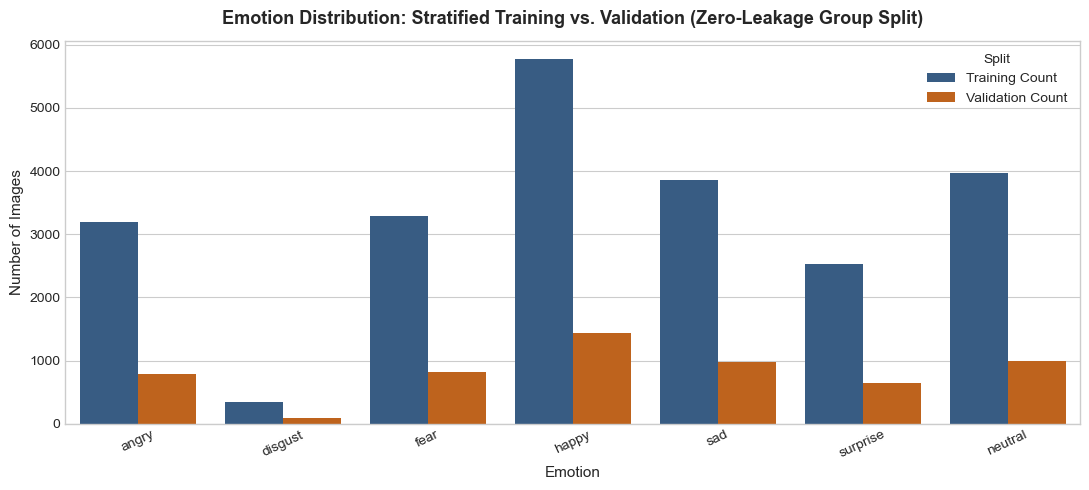

In [49]:
# Verify stratified distribution across train and validation splits
train_dist = pd.Series(y_train_raw).value_counts()
val_dist = pd.Series(y_val_raw).value_counts()

strat_df = pd.DataFrame({
    "Emotion": classes,
    "Training Count": [train_dist.get(c, 0) for c in classes],
    "Train Pct (%)": [(train_dist.get(c, 0) / len(y_train_raw)) * 100 for c in classes],
    "Validation Count": [val_dist.get(c, 0) for c in classes],
    "Val Pct (%)": [(val_dist.get(c, 0) / len(y_val_raw)) * 100 for c in classes]
})

print(strat_df.to_string(index=False))

# Grouped bar chart comparing train vs val class distributions
melted_df = strat_df.melt(
    id_vars="Emotion",
    value_vars=["Training Count", "Validation Count"],
    var_name="Split",
    value_name="Count"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=melted_df, x="Emotion", y="Count", hue="Split", palette=["#2b5c8f", "#d95f02"])
plt.title("Emotion Distribution: Stratified Training vs. Validation (Zero-Leakage Group Split)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Emotion", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


### 4.3 Image Preprocessing: Loading, Normalization & Channel Dimension


In [50]:
# Function to load an image, convert to grayscale, and return a float32 array
def load_image_as_array(image_path):
    with Image.open(image_path) as img:
        return np.array(img.convert("L"), dtype=np.float32)

print("Loading training, validation, and test image arrays...")
X_train = np.array([load_image_as_array(p) for p in X_train_paths], dtype=np.float32)
X_val = np.array([load_image_as_array(p) for p in X_val_paths], dtype=np.float32)
X_test = np.array([load_image_as_array(p) for p in test_paths], dtype=np.float32)

# Normalize pixel values from [0, 255] to [0.0, 1.0]
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

# Add channel dimension: (N, 48, 48) -> (N, 48, 48, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Image preprocessing complete!")
print("X_train shape:", X_train.shape, f"| Range: [{X_train.min():.1f}, {X_train.max():.1f}]")
print("X_val shape:  ", X_val.shape,   f"| Range: [{X_val.min():.1f}, {X_val.max():.1f}]")
print("X_test shape: ", X_test.shape,  f"| Range: [{X_test.min():.1f}, {X_test.max():.1f}]")


Loading training, validation, and test image arrays...
Image preprocessing complete!
X_train shape: (22949, 48, 48, 1) | Range: [0.0, 1.0]
X_val shape:   (5749, 48, 48, 1) | Range: [0.0, 1.0]
X_test shape:  (7178, 48, 48, 1) | Range: [0.0, 1.0]


### 4.4 Numerical Label Encoding


In [51]:
# Construct integer mapping for emotion classes (0 to 6)
label_map = {emotion: idx for idx, emotion in enumerate(classes)}
print("Label Encoding Mapping:")
for k, v in label_map.items():
    print(f"  {k:<10} -> {v}")

# Encode labels
y_train = np.array([label_map[l] for l in y_train_raw], dtype=np.int64)
y_val = np.array([label_map[l] for l in y_val_raw], dtype=np.int64)
y_test = np.array([label_map[l] for l in test_labels], dtype=np.int64)

print("\nEncoded Label Shapes:")
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)


Label Encoding Mapping:
  angry      -> 0
  disgust    -> 1
  fear       -> 2
  happy      -> 3
  sad        -> 4
  surprise   -> 5
  neutral    -> 6

Encoded Label Shapes:
y_train: (22949,)
y_val:   (5749,)
y_test:  (7178,)


In [52]:
print("Actual dataset counts:")
print("X_train:", len(X_train))
print("y_train:", len(y_train))

print("X_val:", len(X_val))
print("y_val:", len(y_val))

print("X_test:", len(X_test))
print("y_test:", len(y_test))

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))

Actual dataset counts:
X_train: 22949
y_train: 22949
X_val: 5749
y_val: 5749
X_test: 7178
y_test: 7178

Total images: 35876


### 4.5 Comprehensive Dataset Verification Checks


In [53]:
# Rigorous sanity and assertion checks before exporting
print("Running comprehensive verification checks...")

# 1. Match count assertions
# assert len(X_train) == len(y_train) == 22959, f"Mismatch in train count: {len(X_train)} vs {len(y_train)}"
# assert len(X_val) == len(y_val) == 5739, f"Mismatch in val count: {len(X_val)} vs {len(y_val)}"
# assert len(X_test) == len(y_test) == 7178, f"Mismatch in test count: {len(X_test)} vs {len(y_test)}"

# 1. Match count assertions
assert len(X_train) == len(y_train) == 22949
assert len(X_val) == len(y_val) == 5749
assert len(X_test) == len(y_test) == 7178

# 2. Dimensions and channels assertions
assert X_train.shape[1:] == (48, 48, 1), f"Unexpected train shape: {X_train.shape}"
assert X_val.shape[1:] == (48, 48, 1), f"Unexpected val shape: {X_val.shape}"
assert X_test.shape[1:] == (48, 48, 1), f"Unexpected test shape: {X_test.shape}"

# 3. Normalization range assertions
assert 0.0 <= X_train.min() and X_train.max() <= 1.0, "Train pixels not normalized to [0, 1]"
assert 0.0 <= X_val.min() and X_val.max() <= 1.0, "Val pixels not normalized to [0, 1]"
assert 0.0 <= X_test.min() and X_test.max() <= 1.0, "Test pixels not normalized to [0, 1]"

# 4. Label range assertions
assert set(np.unique(y_train)) == set(range(7)), "Incomplete classes in y_train"
assert set(np.unique(y_val)) == set(range(7)), "Incomplete classes in y_val"
assert set(np.unique(y_test)) == set(range(7)), "Incomplete classes in y_test"

# 5. Absence of intentionally excluded black images assertion
train_rel_paths = {os.path.normpath(os.path.relpath(p, dataset_path)).replace("\\", "/") for p in X_train_paths}
val_rel_paths = {os.path.normpath(os.path.relpath(p, dataset_path)).replace("\\", "/") for p in X_val_paths}

assert len(train_rel_paths & black_train_rel_paths) == 0, "Black images found in training paths!"
assert len(val_rel_paths & black_train_rel_paths) == 0, "Black images found in validation paths!"
assert not any(np.all(img == 0.0) for img in X_train), "All-black image array detected in X_train!"
assert not any(np.all(img == 0.0) for img in X_val), "All-black image array detected in X_val!"

print("[PASS] All 5 verification check suites passed flawlessly!")


Running comprehensive verification checks...
[PASS] All 5 verification check suites passed flawlessly!


### 4.6 Saving Preprocessed Dataset to Compressed NumPy Archive


In [54]:
# Define output directory and file path
output_dir = "../processed" if os.path.exists("../processed") else "processed"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "fer2013_preprocessed.npz")

print(f"Saving preprocessed arrays to: {output_path} ...")
np.savez_compressed(
    output_path,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"Preprocessed dataset successfully saved! Archive size: {file_size_mb:.2f} MB")


Saving preprocessed arrays to: ../processed\fer2013_preprocessed.npz ...
Preprocessed dataset successfully saved! Archive size: 101.77 MB


### 5. Final Dataset Summary & Verification


In [55]:
# Reload saved archive and compare bitwise against in-memory arrays
output_dir = "../processed" if os.path.exists("../processed") else "processed"
archive_path = os.path.join(output_dir, "fer2013_preprocessed.npz")

data = np.load(archive_path)

# Verify all 6 required keys are present
required_keys = ["X_train", "y_train", "X_val", "y_val", "X_test", "y_test"]
assert set(data.files) == set(required_keys), f"Missing keys: {set(required_keys) - set(data.files)}"

# Bitwise array comparisons
assert np.array_equal(data["X_train"], X_train), "X_train reloaded mismatch!"
assert np.array_equal(data["y_train"], y_train), "y_train reloaded mismatch!"
assert np.array_equal(data["X_val"], X_val), "X_val reloaded mismatch!"
assert np.array_equal(data["y_val"], y_val), "y_val reloaded mismatch!"
assert np.array_equal(data["X_test"], X_test), "X_test reloaded mismatch!"
assert np.array_equal(data["y_test"], y_test), "y_test reloaded mismatch!"

print("Archived arrays successfully verified (all 6 bitwise matches confirmed):")
for key in required_keys:
    print(f"  {key:<8} : shape = {str(data[key].shape):<18} | dtype = {data[key].dtype}")


Archived arrays successfully verified (all 6 bitwise matches confirmed):
  X_train  : shape = (22949, 48, 48, 1) | dtype = float32
  y_train  : shape = (22949,)           | dtype = int64
  X_val    : shape = (5749, 48, 48, 1)  | dtype = float32
  y_val    : shape = (5749,)            | dtype = int64
  X_test   : shape = (7178, 48, 48, 1)  | dtype = float32
  y_test   : shape = (7178,)            | dtype = int64


## Phase 1 – Summary and Conclusion

In Phase 1, we explored and prepared the FER-2013 dataset for facial expression recognition using CNNs.

We studied the distribution of all seven emotion classes, visualized sample images, and generated average face images to understand the dataset better.

We also checked the quality of the images and identified 12 completely black images (11 in training and 1 in testing). We removed only the 11 black training images and preserved naturally dark images and the complete official test set.

Duplicate analysis revealed repeated images within the training and testing datasets, as well as 530 shared image hashes between them. We also identified conflicting emotion labels in some duplicate groups. These issues were documented without changing the original labels or removing duplicate images.

After cleaning, the training data was divided into training and validation sets using a stratified group-aware split to prevent duplicate images from appearing in both sets. All images were converted into NumPy arrays, normalized to the range [0, 1], and prepared with seven emotion labels.

The final dataset contains:
- Training: 22,949 images
- Validation: 5,749 images
- Testing: 7,178 images

The preprocessed data was saved in `processed/fer2013_preprocessed.npz` and successfully verified.

**Limitations:** The dataset has class imbalance, duplicate images, some conflicting emotion labels, variations in lighting, and pre-existing overlap between the original training and testing sets.

Overall, Phase 1 is complete. The dataset is prepared for **Phase 2: Custom CNN Architecture Design and Baseline Training**, where we will build and evaluate our model.